# DS471 Machine Learning Project — Heart Disease Prediction

**Dataset:** UCI Heart Disease, Cleveland database (`processed.cleveland.data`) — https://archive.ics.uci.edu/dataset/45/heart+disease
**Group members:** Abdulwahab Almutairi (S230049170), Abdulaziz S Aljohani (S230028494), Mohammad Abdulwahab Saeed (S230045528), Yousuf Abdulmannan (S230018039)

**GitHub repository:** https://github.com/As-m2023/ds471-heart-disease-ml

**Task:** predict whether a patient has angiographically confirmed coronary heart disease (≥ 50% narrowing of a major vessel) from 13 clinical attributes.

| Stage | Content |
|---|---|
| 1 | Data understanding, quality checks, cleaning, encoding, scaling, feature engineering, EDA, feature relevance |
| 2 | Stratified 60 / 20 / 20 train / validation / test split |
| 3 | Logistic Regression, Decision Tree, Gradient Boosting, Neural Network (Keras MLP) |
| 4 | Hyperparameter search with repeated stratified 5-fold CV (ROC-AUC); learning curves; NN training/validation curves |
| 5 | One-time test-set evaluation, confidence intervals, model comparison |

Every random operation uses `SEED = 42`.

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, learning_curve, validation_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score, log_loss, classification_report)

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"savefig.dpi": 160, "font.family": "serif", "axes.spines.top": False, "axes.spines.right": False})
C_NO, C_YES = "#2A9D8F", "#E76F51"          # no disease / disease
MODEL_COLORS = {"Logistic Regression": "#264653", "Decision Tree": "#E9C46A",
                "Gradient Boosting": "#F4A261", "Neural Network": "#E76F51"}

def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()
print("TensorFlow", tf.__version__)

I0000 00:00:1795096411.293551     283 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795096412.838761     283 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


---
# Stage 1 — Data Cleaning, Preparation and Exploration
## 1.1 Load the data
The Cleveland file has no header and uses `?` for missing values. The column names follow the UCI documentation. (With internet access to UCI, the same data can be loaded with `ucimlrepo`: `fetch_ucirepo(id=45)`.)

In [2]:
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
        "exang", "oldpeak", "slope", "ca", "thal", "num"]
raw = pd.read_csv("data/processed.cleveland.data", names=COLS, na_values="?")
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1.2 Features, target and data types

In [3]:
dictionary = pd.DataFrame([
    ["age", "Age in years", "numeric"],
    ["sex", "1 = male, 0 = female", "binary"],
    ["cp", "Chest-pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic", "nominal"],
    ["trestbps", "Resting blood pressure (mm Hg)", "numeric"],
    ["chol", "Serum cholesterol (mg/dl)", "numeric"],
    ["fbs", "Fasting blood sugar > 120 mg/dl (1 = true)", "binary"],
    ["restecg", "Resting ECG: 0 normal, 1 ST-T abnormality, 2 left-ventricular hypertrophy", "nominal"],
    ["thalach", "Maximum heart rate achieved in exercise test (bpm)", "numeric"],
    ["exang", "Exercise-induced angina (1 = yes)", "binary"],
    ["oldpeak", "ST depression induced by exercise relative to rest (mm)", "numeric"],
    ["slope", "Slope of peak-exercise ST segment: 1 up, 2 flat, 3 down", "nominal"],
    ["ca", "Number of major vessels coloured by fluoroscopy (0-3)", "ordinal (count)"],
    ["thal", "Thallium stress test: 3 normal, 6 fixed defect, 7 reversible defect", "nominal"],
    ["num", "Angiographic diagnosis: 0 = < 50% narrowing, 1-4 = > 50% narrowing (severity)", "target"],
], columns=["Feature", "Meaning", "Type"])
display(dictionary)
print(raw.dtypes.value_counts())

,Feature,Meaning,Type
0,age,Age in years,numeric
1,sex,"1 = male, 0 = female",binary
2,cp,"Chest-pain type: 1 typical angina, 2 atypical ...",nominal
3,trestbps,Resting blood pressure (mm Hg),numeric
4,chol,Serum cholesterol (mg/dl),numeric
5,fbs,Fasting blood sugar > 120 mg/dl (1 = true),binary
6,restecg,"Resting ECG: 0 normal, 1 ST-T abnormality, 2 l...",nominal
7,thalach,Maximum heart rate achieved in exercise test (...,numeric
8,exang,Exercise-induced angina (1 = yes),binary
9,oldpeak,ST depression induced by exercise relative to ...,numeric


float64    13
int64       1
Name: count, dtype: int64


All columns are stored as float because pandas reads `?` as NaN. Seven attributes are categorical even though they are coded as numbers: **one-hot encoding is required for the nominal ones (`cp`, `restecg`, `slope`, `thal`)**, because treating, e.g., chest-pain codes 1–4 as numbers would impose a false order and distance between categories.

### Target definition
`num` ranges from 0 to 4. Following the standard use of this dataset (and the UCI description), it is **binarised: 0 = no disease, 1 = disease (num ≥ 1)**. The severity classes 1–4 are too small to model separately (class 4 has only 13 patients), and the clinical question is whether disease is present.

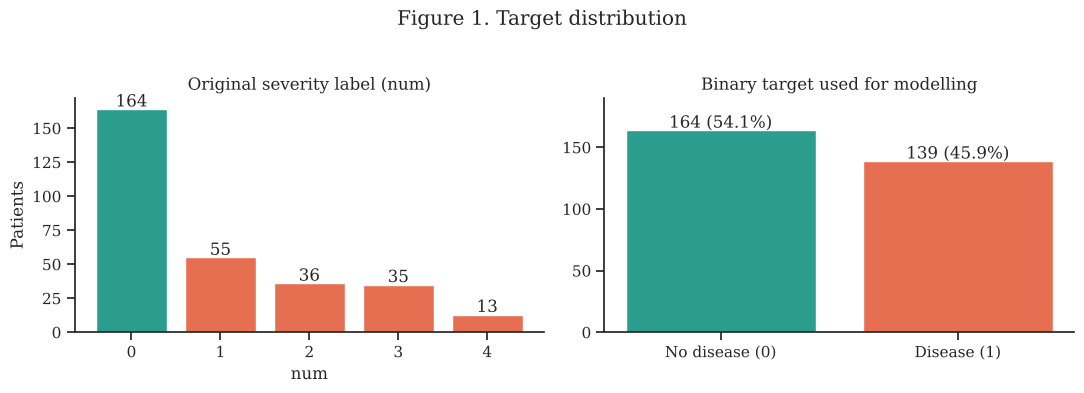

In [4]:
df = raw.copy()
df["target"] = (df["num"] > 0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sev = df["num"].value_counts().sort_index()
axes[0].bar(sev.index.astype(int).astype(str), sev.values, color=[C_NO] + [C_YES] * 4)
for i, v in enumerate(sev.values): axes[0].text(i, v + 2, str(v), ha="center")
axes[0].set_title("Original severity label (num)"); axes[0].set_xlabel("num"); axes[0].set_ylabel("Patients")
tc = df["target"].value_counts().sort_index()
axes[1].bar(["No disease (0)", "Disease (1)"], tc.values, color=[C_NO, C_YES])
for i, v in enumerate(tc.values): axes[1].text(i, v + 2, f"{v} ({v / len(df):.1%})", ha="center")
axes[1].set_title("Binary target used for modelling"); axes[1].set_ylim(0, 190)
fig.suptitle("Figure 1. Target distribution", y=1.03)
save("f01_target")

The binary target is **almost balanced (54.1% no disease, 45.9% disease)**, so no resampling is needed. Stratified splitting is still used so that every subset keeps this ratio.

## 1.3 Missing values, duplicates and inconsistent data

In [5]:
print("Missing values per column:\n", df.isna().sum()[lambda s: s > 0])
print("Rows with any missing value:", df.isna().any(axis=1).sum())
print("Duplicate rows:", df.duplicated().sum())

valid = {"sex": {0, 1}, "cp": {1, 2, 3, 4}, "fbs": {0, 1}, "restecg": {0, 1, 2}, "exang": {0, 1},
         "slope": {1, 2, 3}, "ca": {0, 1, 2, 3}, "thal": {3, 6, 7}}
for c, ok in valid.items():
    bad = (~df[c].dropna().isin(ok)).sum()
    print(f"{c:8s} invalid codes: {bad}   counts: {df[c].value_counts(dropna=False).sort_index().to_dict()}")

ranges = {"age": (18, 100), "trestbps": (70, 250), "chol": (100, 650), "thalach": (60, 220), "oldpeak": (0, 7)}
for c, (lo, hi) in ranges.items():
    print(f"{c:8s} min={df[c].min():6.1f} max={df[c].max():6.1f}  outside plausible [{lo},{hi}]: {((df[c] < lo) | (df[c] > hi)).sum()}")
print("thalach above the age-predicted maximum (220 - age):", (df.thalach > 220 - df.age).sum())

Missing values per column:
 ca      4
thal    2
dtype: int64
Rows with any missing value: 6
Duplicate rows: 0
sex      invalid codes: 0   counts: {0.0: 97, 1.0: 206}
cp       invalid codes: 0   counts: {1.0: 23, 2.0: 50, 3.0: 86, 4.0: 144}
fbs      invalid codes: 0   counts: {0.0: 258, 1.0: 45}
restecg  invalid codes: 0   counts: {0.0: 151, 1.0: 4, 2.0: 148}
exang    invalid codes: 0   counts: {0.0: 204, 1.0: 99}
slope    invalid codes: 0   counts: {1.0: 142, 2.0: 140, 3.0: 21}
ca       invalid codes: 0   counts: {0.0: 176, 1.0: 65, 2.0: 38, 3.0: 20, nan: 4}
thal     invalid codes: 0   counts: {3.0: 166, 6.0: 18, 7.0: 117, nan: 2}
age      min=  29.0 max=  77.0  outside plausible [18,100]: 0
trestbps min=  94.0 max= 200.0  outside plausible [70,250]: 0
chol     min= 126.0 max= 564.0  outside plausible [100,650]: 0
thalach  min=  71.0 max= 202.0  outside plausible [60,220]: 0
oldpeak  min=   0.0 max=   6.2  outside plausible [0,7]: 0
thalach above the age-predicted maximum (220 - age): 

**Findings and decisions**
- **Missing values:** 6 values in 6 rows (`ca`: 4, `thal`: 2), i.e. 2% of patients. With only 303 patients, deleting rows is wasteful. The values will be **imputed with the most frequent category** (mode), because both are categorical. The imputer is **fitted on the training set only** inside the pipeline, so no information leaks from validation/test data.
- **Duplicates:** none.
- **Invalid codes / impossible values:** none. All categorical codes match the UCI documentation, and all measurements are within physiologically plausible ranges.
- **Apparent inconsistency checked and accepted:** 66 patients reached a heart rate above the rule-of-thumb maximum "220 − age". This is not a data error: the formula is only a population estimate with a standard deviation of about 10–12 bpm, so healthy, fit patients often exceed it.
- **Rare-category inconsistency:** `restecg = 1` (ST-T abnormality) occurs in only **4 patients**. A one-hot column with 4 cases cannot be learned reliably and may be missing from a fold entirely. Both code 1 and code 2 mean an *abnormal* resting ECG, so they are **merged into one binary feature `restecg_abnormal`**.

In [6]:
df["restecg_abnormal"] = (df["restecg"] > 0).astype(int)
print(df.groupby("restecg_abnormal")["target"].agg(["count", "mean"]).round(3))

                  count   mean
restecg_abnormal              
0                   151  0.371
1                   152  0.546


## 1.4 Outliers

Outliers per feature (1.5*IQR): {'age': 0, 'trestbps': 9, 'chol': 5, 'thalach': 1, 'oldpeak': 5}
Rows with at least one outlier: 19
Most extreme values: {'trestbps': np.float64(200.0), 'chol': np.float64(564.0), 'oldpeak': np.float64(6.2)} | min thalach: 71.0
Skewness: {'age': -0.21, 'trestbps': 0.71, 'chol': 1.14, 'thalach': -0.54, 'oldpeak': 1.27}


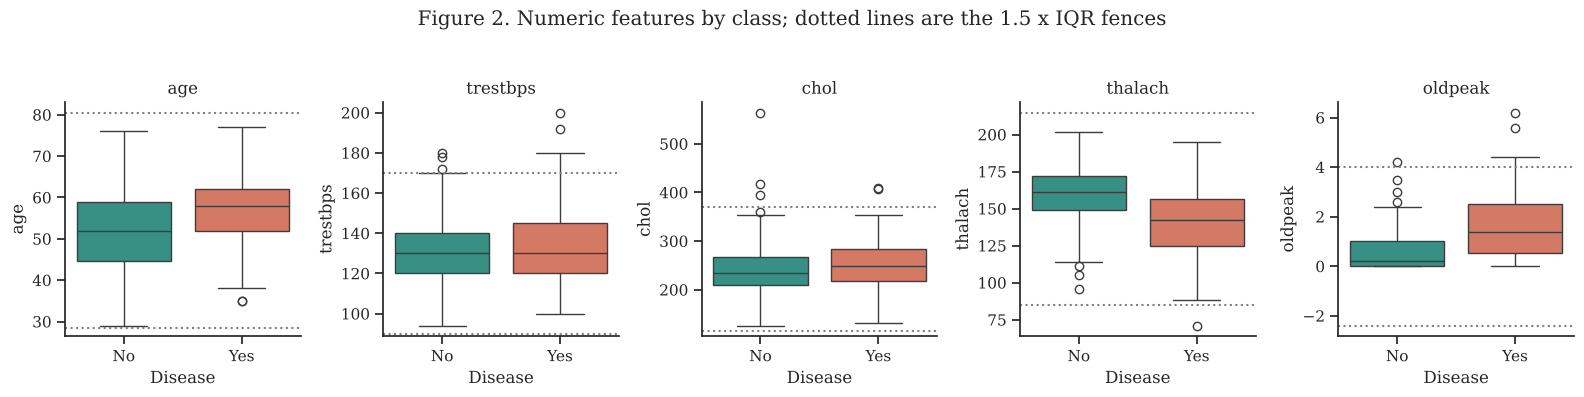

In [7]:
NUM = ["age", "trestbps", "chol", "thalach", "oldpeak"]
q1, q3 = df[NUM].quantile(.25), df[NUM].quantile(.75); iqr = q3 - q1
out = (df[NUM] < q1 - 1.5 * iqr) | (df[NUM] > q3 + 1.5 * iqr)
print("Outliers per feature (1.5*IQR):", out.sum().to_dict())
print("Rows with at least one outlier:", out.any(axis=1).sum())
print("Most extreme values:", {c: df[c].max() for c in ["trestbps", "chol", "oldpeak"]}, "| min thalach:", df.thalach.min())
print("Skewness:", df[NUM].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, c in zip(axes, NUM):
    sns.boxplot(data=df, x="target", y=c, ax=ax, palette=[C_NO, C_YES], hue="target", legend=False)
    ax.axhline(q3[c] + 1.5 * iqr[c], ls=":", color="grey"); ax.axhline(q1[c] - 1.5 * iqr[c], ls=":", color="grey")
    ax.set_xticklabels(["No", "Yes"]); ax.set_xlabel("Disease"); ax.set_title(c)
fig.suptitle("Figure 2. Numeric features by class; dotted lines are the 1.5 x IQR fences", y=1.04)
save("f02_outliers")

**Decision: cap (winsorise) instead of delete.** Only 19 rows (6%) contain an outlier, and the values are extreme but medically possible (e.g., cholesterol 564 mg/dl, ST depression 6.2 mm). Deleting them would waste data in an already small dataset and remove genuine high-risk patients. Leaving them unchanged, however, would let a handful of points pull the coefficients of Logistic Regression and the weights of the Neural Network. The values are therefore **clipped to the 1.5 × IQR fences**. The fences are **learned from the training data only** by a custom `IQRCapper` transformer in the pipeline. **Tree-based models (Decision Tree, Gradient Boosting) use the raw values**, because splits depend only on the rank order of values, which capping would not change in a useful way. The remaining skewness (chol 1.1, oldpeak 1.3) is moderate after capping, so no log transform is needed.

## 1.5 Feature engineering

In [8]:
# Composite clinical feature: number of ischaemia indicators present (0-5).
# Each indicator is a recognised sign of coronary disease; thresholds are fixed clinical rules, not learned from data,
# so the feature can be created before the split without leakage. Missing ca/thal count as "not present".
signs = pd.DataFrame({
    "asymptomatic_cp": df.cp == 4,          # chest pain without typical symptoms is the highest-risk group in this data
    "exercise_angina": df.exang == 1,
    "st_depression":  df.oldpeak >= 1.0,
    "vessels_blocked": df.ca.fillna(0) > 0,
    "thal_defect":    df.thal.fillna(3) > 3,
})
df["ischaemia_signs"] = signs.sum(axis=1)
print(pd.crosstab(df.ischaemia_signs, df.target, margins=True))
print("\nCorrelation with target: %.3f" % df.ischaemia_signs.corr(df.target))
print("Strongest single original feature correlation: %.3f" %
      df[["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "exang"]].corrwith(df.target).abs().max())

target             0    1  All
ischaemia_signs               
0                 55    3   58
1                 61   13   74
2                 35   17   52
3                 11   34   45
4                  2   43   45
5                  0   29   29
All              164  139  303

Correlation with target: 0.712
Strongest single original feature correlation: 0.460


**`ischaemia_signs`** counts how many of five recognised warning signs a patient shows: asymptomatic chest pain, exercise-induced angina, ST depression ≥ 1 mm, at least one blocked vessel, and a thallium defect. A cardiologist reasons in the same cumulative way. The feature has a much higher correlation with the target than any single original attribute, and disease prevalence rises steadily from about 5% (0 signs) to 100% (5 signs). It gives the linear models a strong, additive risk signal.

**Encoding and scaling plan (implemented as a `ColumnTransformer` that is fitted on training data only):**

| Group | Columns | Linear model & NN | Tree models |
|---|---|---|---|
| Continuous | age, trestbps, chol, thalach, oldpeak, ischaemia_signs | median impute → IQR cap → standardise | median impute (raw scale) |
| Ordinal count | ca | mode impute → standardise | mode impute |
| Binary | sex, fbs, exang, restecg_abnormal | unchanged (0/1) | unchanged |
| Nominal | cp, slope, thal | mode impute → **one-hot** | mode impute → **one-hot** |

Standardisation is needed because Logistic Regression's penalty and the Neural Network's gradient descent are sensitive to feature scale (cholesterol is in the hundreds; oldpeak is below 7). `ca` is kept as a single ordered number because "more blocked vessels = higher risk" is a real order. Imputers use the median (robust to outliers) for continuous variables and the mode for categorical ones.

## 1.6 Exploratory data analysis

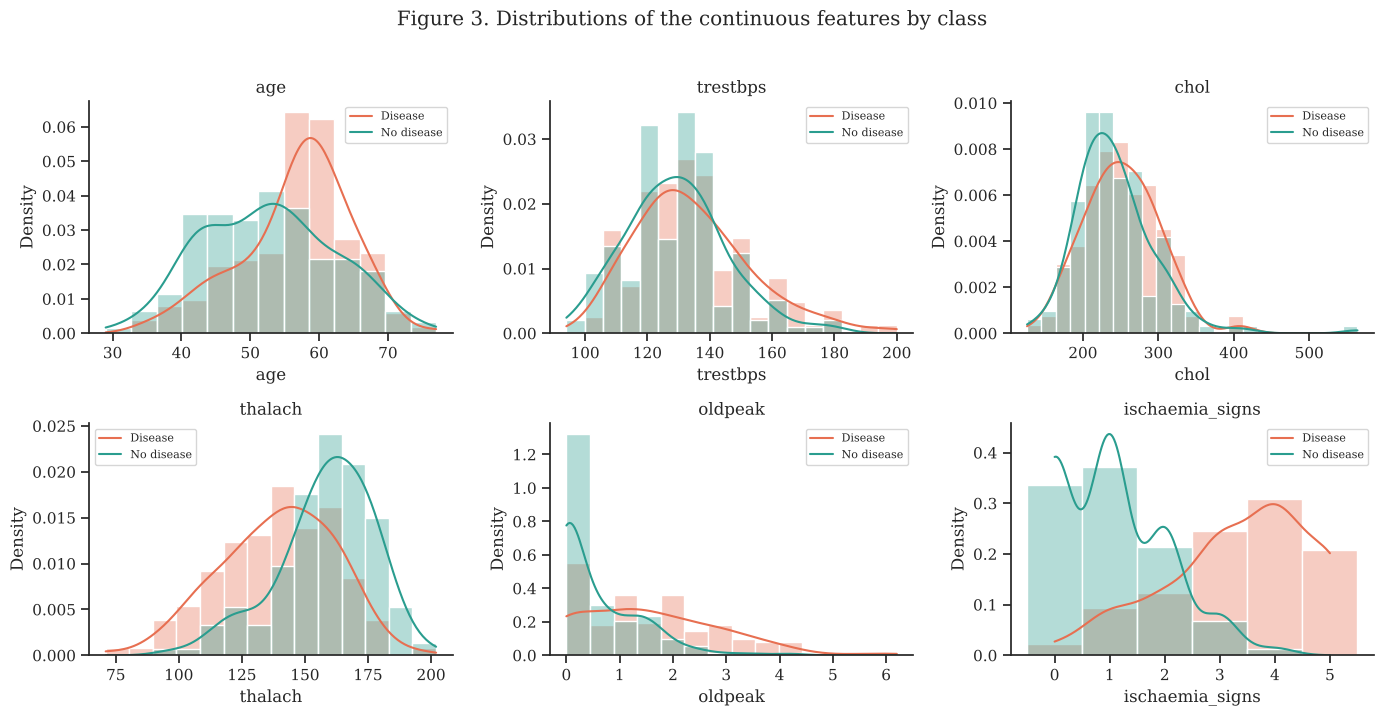

In [9]:
CONT = ["age", "trestbps", "chol", "thalach", "oldpeak", "ischaemia_signs"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), CONT):
    sns.histplot(data=df, x=c, hue="target", kde=True, stat="density", common_norm=False, ax=ax,
                 palette=[C_NO, C_YES], alpha=0.35, discrete=(c == "ischaemia_signs"))
    ax.legend(["Disease", "No disease"], fontsize=8); ax.set_title(c)
fig.suptitle("Figure 3. Distributions of the continuous features by class", y=1.02)
save("f03_numeric_dists")

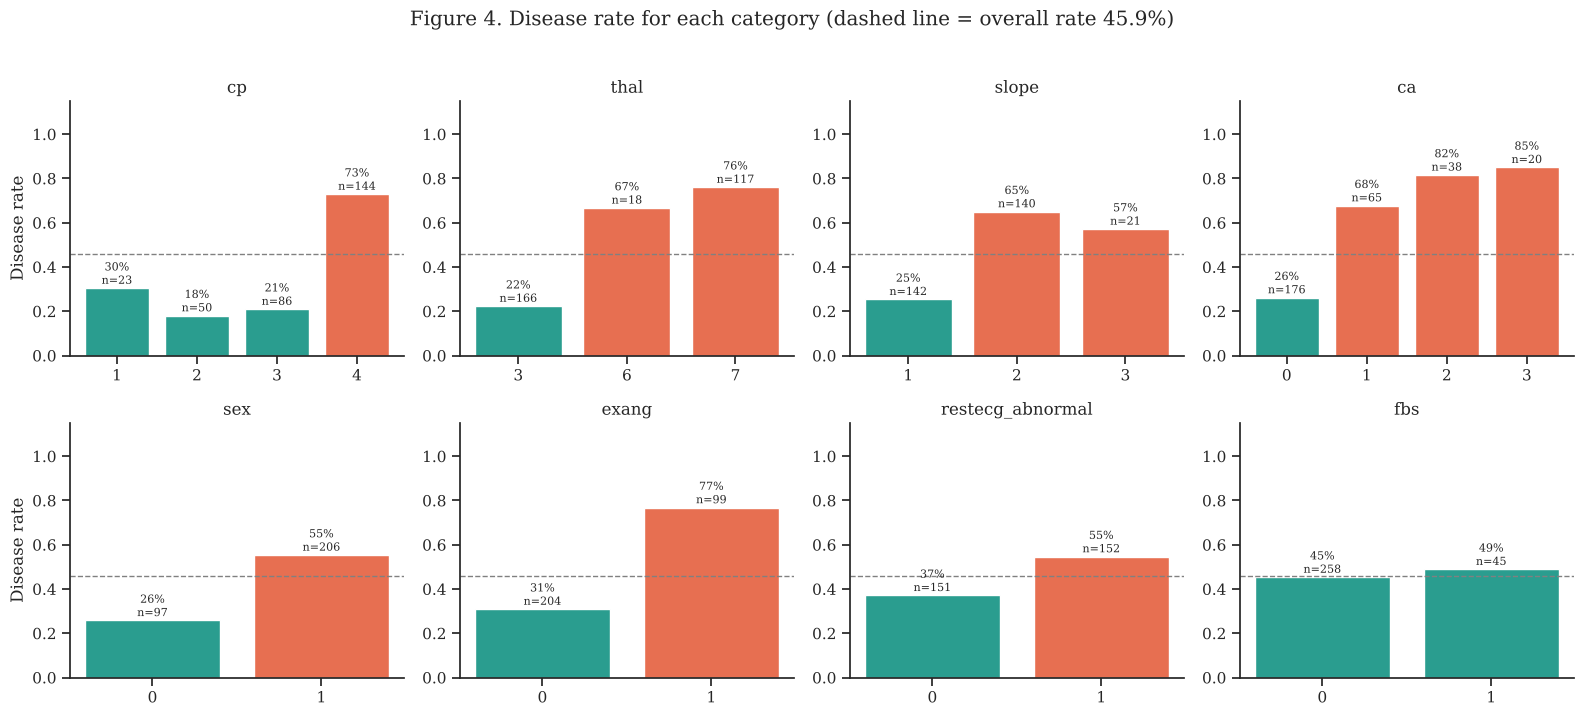

In [10]:
CATS = ["cp", "thal", "slope", "ca", "sex", "exang", "restecg_abnormal", "fbs"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), CATS):
    g = df.groupby(c)["target"].agg(["mean", "count"])
    ax.bar(g.index.astype(int).astype(str), g["mean"], color=[C_YES if m > 0.5 else C_NO for m in g["mean"]])
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, m + 0.02, f"{m:.0%}\nn={n}", ha="center", fontsize=8)
    ax.axhline(df.target.mean(), ls="--", color="grey", lw=1)
    ax.set_ylim(0, 1.15); ax.set_title(c); ax.set_ylabel("Disease rate" if c in ("cp", "sex") else "")
fig.suptitle("Figure 4. Disease rate for each category (dashed line = overall rate 45.9%)", y=1.02)
save("f04_categorical_rates")

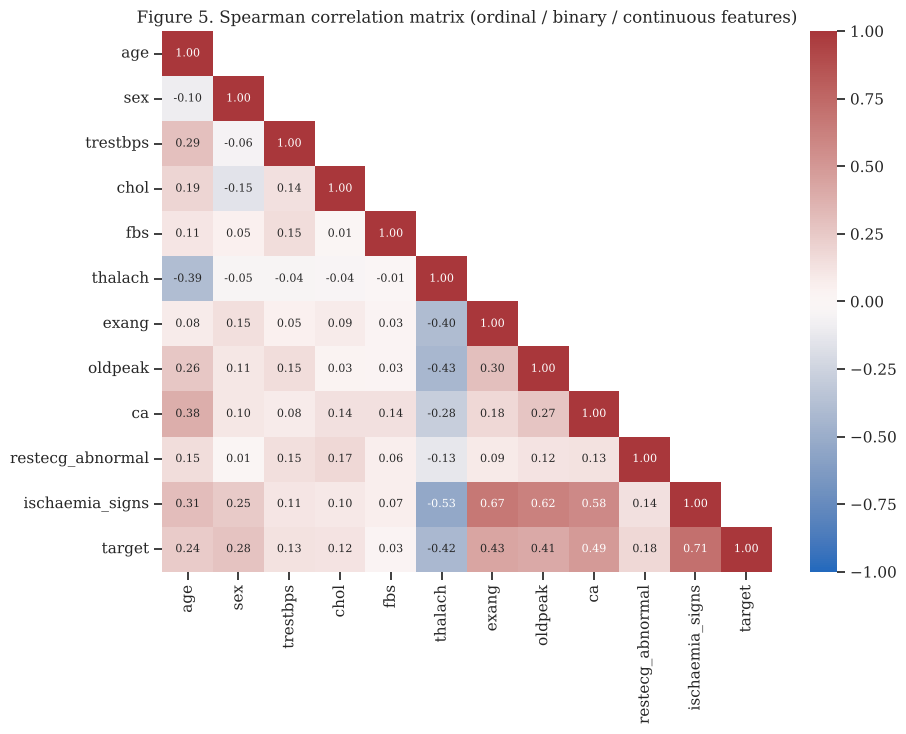

In [11]:
corr_cols = ["age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca", "restecg_abnormal", "ischaemia_signs", "target"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Figure 5. Spearman correlation matrix (ordinal / binary / continuous features)")
save("f05_correlation")

**EDA findings**
- **Exercise-test results dominate.** Patients with disease reach a lower maximum heart rate (`thalach`), have larger ST depression (`oldpeak`), and much more often have exercise-induced angina (77% vs 31% disease rate).
- **Categorical risk patterns are strong.** Asymptomatic chest pain (`cp = 4`) has a 73% disease rate against 18–30% for the other pain types — counter-intuitive, but typical of this referral population. A reversible thallium defect (`thal = 7`) gives 76%. Disease rate also rises monotonically with the number of blocked vessels (`ca`: 26% → 85%), which justifies treating `ca` as ordinal. Men are affected more often than women (55% vs 26%).
- **Weak predictors:** cholesterol, resting blood pressure and fasting blood sugar differ very little between classes (fbs: 45% vs 49%). This is consistent with the literature on this dataset.
- **No severe multicollinearity.** The largest correlation between two original predictors is about |0.4| (thalach vs age / oldpeak), so no features need to be removed. The engineered `ischaemia_signs` naturally correlates with its components.

## 1.7 Most relevant features
Statistical association with the target was tested with the **chi-square test** for categorical features and the **Mann–Whitney U test** for continuous ones (non-parametric, so skew and outliers do not matter). **Mutual information** measures any, including non-linear, dependency.

,test,statistic,p_value,mutual_info,significant (p<0.05)
feature,,,,,
ischaemia_signs,Mann-Whitney U,20549.5000,0.0000,0.3192,True
thal,chi-square,82.6845,0.0000,0.1430,True
cp,chi-square,81.8158,0.0000,0.1421,True
ca,chi-square,72.6169,0.0000,0.1258,True
oldpeak,Mann-Whitney U,16759.0000,0.0000,0.1027,True
exang,chi-square,54.6864,0.0000,0.0964,True
chol,Mann-Whitney U,12997.5000,0.0354,0.0893,True
slope,chi-square,45.7846,0.0000,0.0779,True
thalach,Mann-Whitney U,5806.5000,0.0000,0.0736,True


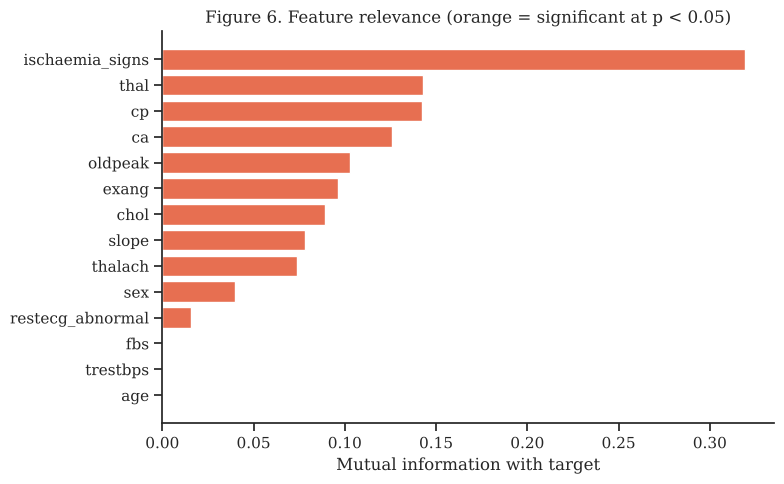

In [12]:
rows = []
for c in ["cp", "thal", "slope", "ca", "sex", "exang", "restecg_abnormal", "fbs"]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df[c].fillna(df[c].mode()[0]), df.target))
    rows.append([c, "chi-square", chi2, p])
for c in CONT:
    u, p = stats.mannwhitneyu(df.loc[df.target == 1, c], df.loc[df.target == 0, c])
    rows.append([c, "Mann-Whitney U", u, p])
rel = pd.DataFrame(rows, columns=["feature", "test", "statistic", "p_value"]).set_index("feature")
Xmi = df[CATS + CONT].copy(); Xmi["ca"] = Xmi["ca"].fillna(0); Xmi["thal"] = Xmi["thal"].fillna(3)
disc = [c in CATS or c == "ischaemia_signs" for c in Xmi.columns]
rel["mutual_info"] = pd.Series(mutual_info_classif(Xmi, df.target, discrete_features=disc, random_state=SEED), index=Xmi.columns)
rel = rel.sort_values("mutual_info", ascending=False)
rel["significant (p<0.05)"] = rel.p_value < 0.05
display(rel.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(rel.index[::-1], rel.mutual_info[::-1], color=[C_YES if s else "#B0B0B0" for s in rel["significant (p<0.05)"][::-1]])
ax.set_xlabel("Mutual information with target"); ax.set_title("Figure 6. Feature relevance (orange = significant at p < 0.05)")
save("f06_relevance")
rel.to_csv("results/feature_relevance.csv")

The most relevant predictors are **`ischaemia_signs`, `thal`, `cp`, `ca`, `oldpeak`, `thalach` and `exang`**. Only `fbs` is **not significant** (p = 0.78). `chol` and `trestbps` are only weakly significant (p ≈ 0.03) and carry little mutual information. The mutual-information estimate for `age` and `trestbps` is 0 even though the Mann–Whitney test detects a shift: with 303 patients, the nearest-neighbour MI estimator cannot resolve such small effects. These weak features are **kept**: there are only 13 attributes, regularisation (L1/L2, tree depth, dropout) can down-weight them, and the models may still use them in interactions. The model-based importances in Stage 4 provide a second check.

---
# Stage 2 — Data Splitting (60 / 20 / 20)

In [13]:
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak",
            "slope", "ca", "thal", "restecg_abnormal", "ischaemia_signs"]
X, y = df[FEATURES], df["target"].values
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
split = pd.DataFrame({"Set": ["Training", "Validation", "Test", "Total"],
                      "Patients": [len(y_train), len(y_val), len(y_test), len(y)],
                      "Disease": [y_train.sum(), y_val.sum(), y_test.sum(), y.sum()]})
split["Share %"] = (split.Patients / len(y) * 100).round(1)
split["Disease %"] = (split.Disease / split.Patients * 100).round(1)
split.to_csv("results/split.csv", index=False); split

,Set,Patients,Disease,Share %,Disease %
0,Training,181,83,59.7,45.9
1,Validation,61,28,20.1,45.9
2,Test,61,28,20.1,45.9
3,Total,303,139,100.0,45.9


**Why 60 / 20 / 20?** The dataset is very small (303 patients).
- A 15% test set would contain only about 46 patients, and each misclassified patient would change accuracy by more than two percentage points. **20% (61 patients, 28 with disease)** gives a more stable final estimate. The same reasoning applies to the validation set, which is used to compare training and validation performance and for the Neural Network's per-epoch monitoring and early stopping.
- The remaining **181 training patients** are still enough for these relatively simple models. To compensate for the smaller training set, hyperparameters are **not** chosen on the single validation set. Instead, **repeated stratified 5-fold cross-validation (5 folds × 3 repeats = 15 fits per setting)** is run inside the training set, which reduces the variance of the tuning estimate.
- **Stratification** keeps the disease rate at about 46% in every subset.
- All learned preprocessing (imputation values, IQR fences, scaler means, one-hot categories) is fitted on the training data — or the training folds — only.

---
# Stage 3 — Model Selection and Development

In [14]:
class IQRCapper(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    # Clip each column to [Q1 - k*IQR, Q3 + k*IQR]; the fences are learned in fit() from training data only.
    def __init__(self, k=1.5): self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lower_, self.upper_ = q1 - self.k * (q3 - q1), q3 + self.k * (q3 - q1)
        self.n_features_in_ = X.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

CONT_F = ["age", "trestbps", "chol", "thalach", "oldpeak", "ischaemia_signs"]
ORD_F, BIN_F, NOM_F = ["ca"], ["sex", "fbs", "exang", "restecg_abnormal"], ["cp", "slope", "thal"]

def make_preprocessor(for_trees=False):
    if for_trees:   # trees: no capping, no scaling
        cont = SimpleImputer(strategy="median"); ordn = SimpleImputer(strategy="most_frequent")
    else:
        cont = Pipeline([("imp", SimpleImputer(strategy="median")), ("cap", IQRCapper()), ("sc", StandardScaler())])
        ordn = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())])
    nom = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("cont", cont, CONT_F), ("ord", ordn, ORD_F),
                              ("bin", "passthrough", BIN_F), ("nom", nom, NOM_F)],
                             verbose_feature_names_out=False)

prep = make_preprocessor().fit(X_train)
FEAT_OUT = list(prep.get_feature_names_out())
print(len(FEAT_OUT), "model inputs:", FEAT_OUT)
print("IQR fences learned on training data:")
print(pd.DataFrame({"lower": prep.named_transformers_["cont"]["cap"].lower_,
                    "upper": prep.named_transformers_["cont"]["cap"].upper_}, index=CONT_F).round(2))

21 model inputs: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ischaemia_signs', 'ca', 'sex', 'fbs', 'exang', 'restecg_abnormal', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']
IQR fences learned on training data:
                 lower  upper
age               28.5   80.5
trestbps          90.0  170.0
chol             104.5  388.5
thalach           95.5  203.5
oldpeak           -2.4    4.0
ischaemia_signs   -3.5    8.5


Four models are developed. The traditional models cover three different families — a **linear model**, a **single tree** and a **boosted ensemble of trees** — and the mandatory **Neural Network** completes the comparison.

| Model | Family | Why it suits this problem |
|---|---|---|
| **Logistic Regression** | Linear, probabilistic | Binary target, small sample (181 training patients) and mostly additive risk factors. It outputs calibrated probabilities and odds ratios that clinicians can interpret. L1/L2 regularisation guards against overfitting with 21 encoded inputs. |
| **Decision Tree** | Rule-based | Handles mixed categorical and numeric data natively, captures interactions (e.g., chest-pain type × thallium result) and produces human-readable if-then rules similar to clinical decision pathways. Its tendency to overfit is controlled with depth limits, minimum leaf size and cost-complexity pruning. |
| **Gradient Boosting** | Ensemble learning (boosting) | Builds many shallow trees sequentially, each correcting the errors of the previous ones. This usually gives the best accuracy on small tabular datasets. Learning rate, depth and subsampling regularise it. |
| **Neural Network (MLP)** | Feed-forward network | Mandatory. Learns non-linear combinations of the 21 encoded inputs. With so few patients it must be small and regularised (dropout, L2, early stopping). |

Each traditional model is a single `Pipeline(preprocessor → classifier)`, so imputation, capping, scaling and encoding are re-fitted inside every CV fold.

In [15]:
models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor()),
                                     ("clf", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEED))]),
    "Decision Tree": Pipeline([("prep", make_preprocessor(for_trees=True)),
                               ("clf", DecisionTreeClassifier(random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor(for_trees=True)),
                                   ("clf", GradientBoostingClassifier(random_state=SEED))]),
}

def build_mlp(n_in, layers=(32,), dropout=0.2, l2=1e-3, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 else None
    net = keras.Sequential([keras.Input(shape=(n_in,))])
    for u in layers:
        net.add(keras.layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout: net.add(keras.layers.Dropout(dropout))
    net.add(keras.layers.Dense(1, activation="sigmoid"))
    net.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return net
build_mlp(len(FEAT_OUT), (32, 16)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

---
# Stage 4 — Training and Hyperparameter Optimisation
**Search strategy:** grid search for Logistic Regression and the Decision Tree (small search spaces); **randomised search (40 samples)** for Gradient Boosting, whose five-dimensional space is too large for a full grid. All searches use **repeated stratified 5-fold CV (3 repeats) on the training set**.

**Selection metric: ROC-AUC.** With a nearly balanced target and a small sample, AUC is the most stable criterion: it uses the full ranking of predicted probabilities instead of one 0.5 cut-off, so it is less sensitive to the random assignment of a few borderline patients to folds. Recall and F1 are recorded alongside.

In [16]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
spaces = {
    "Logistic Regression": ("grid", {"clf__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10, 100],
                                     "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": ("grid", {"clf__max_depth": [2, 3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
                               "clf__criterion": ["gini", "entropy"], "clf__ccp_alpha": [0.0, 0.005, 0.01, 0.02]}),
    "Gradient Boosting": ("random", {"clf__n_estimators": [50, 100, 150, 200, 300, 400],
                                     "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
                                     "clf__max_depth": [1, 2, 3, 4], "clf__subsample": [0.6, 0.8, 1.0],
                                     "clf__min_samples_leaf": [1, 5, 10, 20]}),
}
scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "accuracy": "accuracy"}
search, rows = {}, []
for name, (kind, space) in spaces.items():
    t0 = time.time()
    if kind == "grid":
        s = GridSearchCV(models[name], space, cv=rcv, scoring=scoring, refit="roc_auc", n_jobs=-1, return_train_score=True)
    else:
        s = RandomizedSearchCV(models[name], space, n_iter=40, cv=rcv, scoring=scoring, refit="roc_auc",
                               n_jobs=-1, return_train_score=True, random_state=SEED)
    s.fit(X_train, y_train); search[name] = s
    r, i = s.cv_results_, s.best_index_
    rows.append({"Model": name, "Search": kind, "Settings tried": len(r["params"]),
                 "Best hyperparameters": {k.replace("clf__", ""): v for k, v in s.best_params_.items()},
                 "CV train AUC": r["mean_train_roc_auc"][i], "CV val AUC": r["mean_test_roc_auc"][i],
                 "CV val AUC std": r["std_test_roc_auc"][i], "CV val F1": r["mean_test_f1"][i],
                 "CV val recall": r["mean_test_recall"][i], "CV val accuracy": r["mean_test_accuracy"][i],
                 "Time (s)": round(time.time() - t0, 1)})
    print(f"{name:20s} AUC={s.best_score_:.4f}  {s.best_params_}")
tuning = pd.DataFrame(rows)
tuning.assign(**{"Best hyperparameters": tuning["Best hyperparameters"].astype(str)}).to_csv("results/tuning.csv", index=False)
tuning.drop(columns="Best hyperparameters").round(4)

Logistic Regression  AUC=0.8912  {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}


Decision Tree        AUC=0.8559  {'clf__ccp_alpha': 0.01, 'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_samples_leaf': 10}


Gradient Boosting    AUC=0.8834  {'clf__subsample': 0.8, 'clf__n_estimators': 50, 'clf__min_samples_leaf': 20, 'clf__max_depth': 4, 'clf__learning_rate': 0.05}


,Model,Search,Settings tried,CV train AUC,CV val AUC,CV val AUC std,CV val F1,CV val recall,CV val accuracy,Time (s)
0,Logistic Regression,grid,32,0.9212,0.8912,0.0477,0.7939,0.7755,0.8157,15.5
1,Decision Tree,grid,280,0.9386,0.8559,0.0495,0.7762,0.7831,0.7899,141.2
2,Gradient Boosting,random,40,0.9631,0.8834,0.0411,0.7996,0.7475,0.8285,55.0


**Selected hyperparameters and why they make sense**
- **Logistic Regression — C = 0.1, L2, `class_weight="balanced"`** (CV AUC 0.891). A moderately strong L2 penalty shrinks the 21 coefficients without removing correlated one-hot columns. Balanced weights slightly raise the cost of missing a diseased patient. The training/validation gap is small (0.921 vs 0.891).
- **Decision Tree — entropy criterion, max_depth 6, min_samples_leaf 10, ccp_alpha 0.01** (CV AUC 0.856). The leaf-size limit and pruning do most of the regularisation: a tree is only allowed to split when at least 10 patients end up in each leaf, which stops it from memorising single patients.
- **Gradient Boosting — 50 trees, learning rate 0.05, depth 4, subsample 0.8, min_samples_leaf 20** (CV AUC 0.883). The search preferred a *small* ensemble with a slow learning rate, large leaves and row subsampling, i.e. strong regularisation. This is expected with only 181 training patients.

## 4.2 Neural Network — randomised search with stratified 5-fold CV
Keras models are tuned with an explicit loop. **16 random configurations** are drawn from: hidden layers {(16), (32), (32, 16), (64, 32)}, dropout {0, 0.2, 0.4}, L2 {0, 0.001, 0.01}, learning rate {0.001, 0.003, 0.01} and batch size {16, 32}. In each fold, the preprocessor is fitted on the fold's training part. Early stopping (patience 20, maximum 300 epochs) watches an inner 20% slice of that part, so the held-out fold is never used for any training decision.

In [17]:
rng = np.random.default_rng(SEED)
grid_nn = {"layers": [(16,), (32,), (32, 16), (64, 32)], "dropout": [0.0, 0.2, 0.4],
           "l2": [0.0, 1e-3, 1e-2], "lr": [1e-3, 3e-3, 1e-2], "batch": [16, 32]}
configs, seen = [], set()
while len(configs) < 16:
    c = {k: v[rng.integers(len(v))] for k, v in grid_nn.items()}
    key = str(c)
    if key not in seen: seen.add(key); configs.append(c)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def cv_mlp(cfg):
    aucs, f1s, eps = [], [], []
    for tr, va in skf.split(X_train, y_train):
        p = make_preprocessor().fit(X_train.iloc[tr])
        xa, xb = p.transform(X_train.iloc[tr]).astype("float32"), p.transform(X_train.iloc[va]).astype("float32")
        keras.utils.set_random_seed(SEED)
        net = build_mlp(xa.shape[1], cfg["layers"], cfg["dropout"], cfg["l2"], cfg["lr"])
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
        h = net.fit(xa, y_train[tr], validation_split=0.2, epochs=300, batch_size=cfg["batch"], verbose=0, callbacks=[es])
        prob = net(xb, training=False).numpy().ravel()
        aucs.append(roc_auc_score(y_train[va], prob)); f1s.append(f1_score(y_train[va], (prob >= .5).astype(int)))
        eps.append(len(h.history["loss"]) - 20)
    return np.mean(aucs), np.std(aucs), np.mean(f1s), int(np.mean(eps))

t0, nn_rows = time.time(), []
for cfg in configs:
    auc_m, auc_s, f1_m, ep = cv_mlp(cfg)
    nn_rows.append({"cfg_id": len(nn_rows), **{k: str(v) for k, v in cfg.items()}, "CV AUC": auc_m, "CV AUC std": auc_s, "CV F1": f1_m, "avg best epoch": ep})
nn_search = pd.DataFrame(nn_rows).sort_values("CV AUC", ascending=False).reset_index(drop=True)
nn_time = time.time() - t0
print("NN search time: %.0f s" % nn_time)
nn_search.to_csv("results/nn_search.csv", index=False)
nn_search.round(4)

NN search time: 378 s


,cfg_id,layers,dropout,l2,lr,batch,CV AUC,CV AUC std,CV F1,avg best epoch
0,14,"(64, 32)",0.0,0.001,0.001,32,0.8919,0.0685,0.8196,14
1,2,"(32, 16)",0.4,0.01,0.01,32,0.8912,0.0705,0.7787,18
2,10,"(64, 32)",0.0,0.001,0.003,16,0.8907,0.0704,0.8208,3
3,5,"(32, 16)",0.2,0.01,0.003,16,0.8883,0.0710,0.7988,27
4,15,"(64, 32)",0.2,0.0,0.01,32,0.8850,0.0641,0.8164,2
5,12,"(64, 32)",0.4,0.001,0.01,16,0.8844,0.0736,0.8211,2
6,9,"(64, 32)",0.2,0.01,0.01,32,0.8836,0.0807,0.7828,10
7,1,"(64, 32)",0.0,0.01,0.001,16,0.8830,0.0889,0.7843,43
8,3,"(64, 32)",0.2,0.0,0.01,16,0.8806,0.0643,0.8164,1
9,4,"(32, 16)",0.2,0.0,0.01,32,0.8772,0.0676,0.8212,2


**NN search result.** The best configuration is **two hidden layers (64 → 32 ReLU), no dropout, L2 = 0.001, learning rate 0.001, batch size 32** (CV AUC 0.892 ± 0.069). The top configurations are within 0.01 AUC of each other, so the network is not very sensitive to these choices on this dataset. Configurations with a high learning rate (0.01) stop after only 1–3 epochs, which means they reach their best validation loss almost immediately and then overfit. The single-layer 16-unit networks rank lowest (slight underfitting). The NN fold-to-fold standard deviation (≈ 0.07) is larger than that of the traditional models (≈ 0.04–0.05), a sign of higher variance.

In [18]:
best_cfg = configs[int(nn_search.iloc[0]["cfg_id"])]
print("Selected NN configuration:", best_cfg)

Selected NN configuration: {'layers': (64, 32), 'dropout': 0.0, 'l2': 0.001, 'lr': 0.001, 'batch': 32}


## 4.3 Neural Network training and validation curves
The selected network is trained on the 181 training patients and **evaluated on the 61 validation patients after every epoch**. Early stopping (patience 40) restores the epoch with the lowest validation loss.

epochs run: 55, best epoch: 15
{'accuracy': 0.9006, 'auc': 0.9381, 'loss': 0.3881, 'val_accuracy': 0.8525, 'val_auc': 0.9378, 'val_loss': 0.3933}


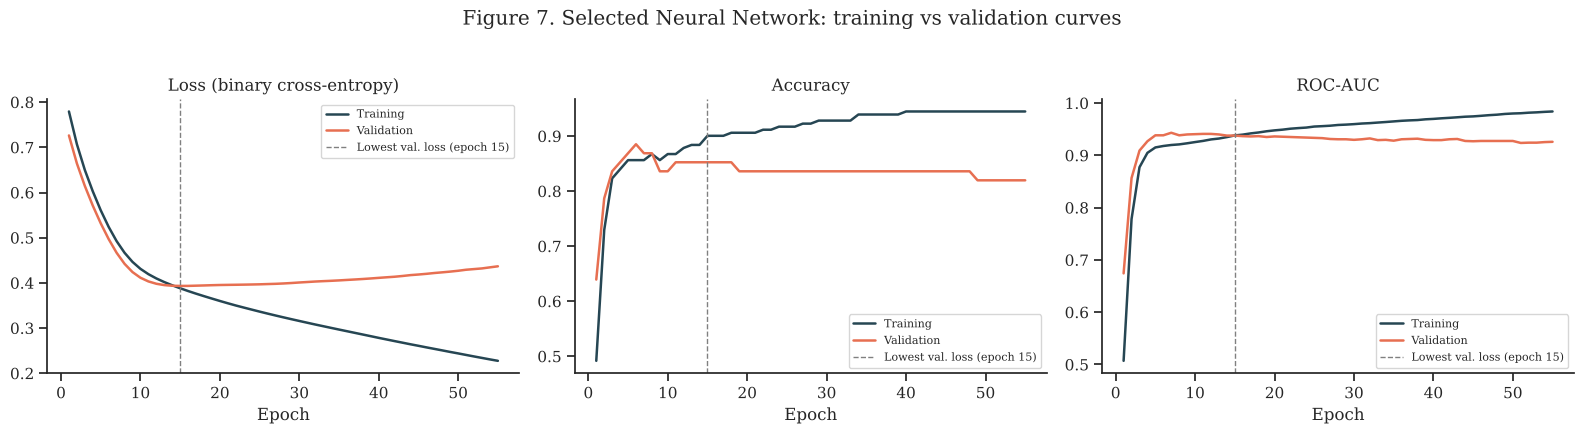

In [19]:
prep_nn = make_preprocessor().fit(X_train)
Xtr = prep_nn.transform(X_train).astype("float32"); Xva = prep_nn.transform(X_val).astype("float32")
Xte = prep_nn.transform(X_test).astype("float32")
keras.utils.set_random_seed(SEED)
mlp = build_mlp(Xtr.shape[1], best_cfg["layers"], best_cfg["dropout"], best_cfg["l2"], best_cfg["lr"])
hist = mlp.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=500, batch_size=best_cfg["batch"], verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)])
H = pd.DataFrame(hist.history); best_ep = int(H.val_loss.idxmin()) + 1
print(f"epochs run: {len(H)}, best epoch: {best_ep}")
print(H.iloc[best_ep - 1].round(4).to_dict())

def curves(H, best, title, fname):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2)); e = np.arange(1, len(H) + 1)
    for ax, m, lab in zip(axes, ["loss", "accuracy", "auc"], ["Loss (binary cross-entropy)", "Accuracy", "ROC-AUC"]):
        ax.plot(e, H[m], color="#264653", lw=1.8, label="Training")
        ax.plot(e, H["val_" + m], color="#E76F51", lw=1.8, label="Validation")
        ax.axvline(best, color="grey", ls="--", lw=1, label=f"Lowest val. loss (epoch {best})")
        ax.set_title(lab); ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
    fig.suptitle(title, y=1.03); save(fname)
curves(H, best_ep, "Figure 7. Selected Neural Network: training vs validation curves", "f07_nn_curves")

**Reading the curves (Figure 7)**
- **Epochs 1–15:** training and validation loss fall together; validation AUC climbs to about 0.94. No underfitting.
- **Epoch 15 (best):** validation loss 0.393, validation accuracy 0.852, validation AUC 0.938; training loss 0.388, accuracy 0.901. The two losses are almost identical, so the model is well balanced.
- **After epoch 15 — overfitting starts:** training loss keeps falling (to about 0.23) and training AUC approaches 0.98, but validation loss rises (to about 0.44) and validation accuracy slips to 0.82. Early stopping halted training at epoch 55 and restored the epoch-15 weights.

### Deliberate over-fitting experiment
For comparison, a large network with no regularisation (128-64-32 units, no dropout, no L2, learning rate 0.01, no early stopping, 300 epochs) is trained on the same data.

parameters: selected 3521 | large 13185
large NN: best val loss 0.336 at epoch 1; final train loss 0.0000, final val loss 1.385, final train acc 1.000, final val acc 0.836


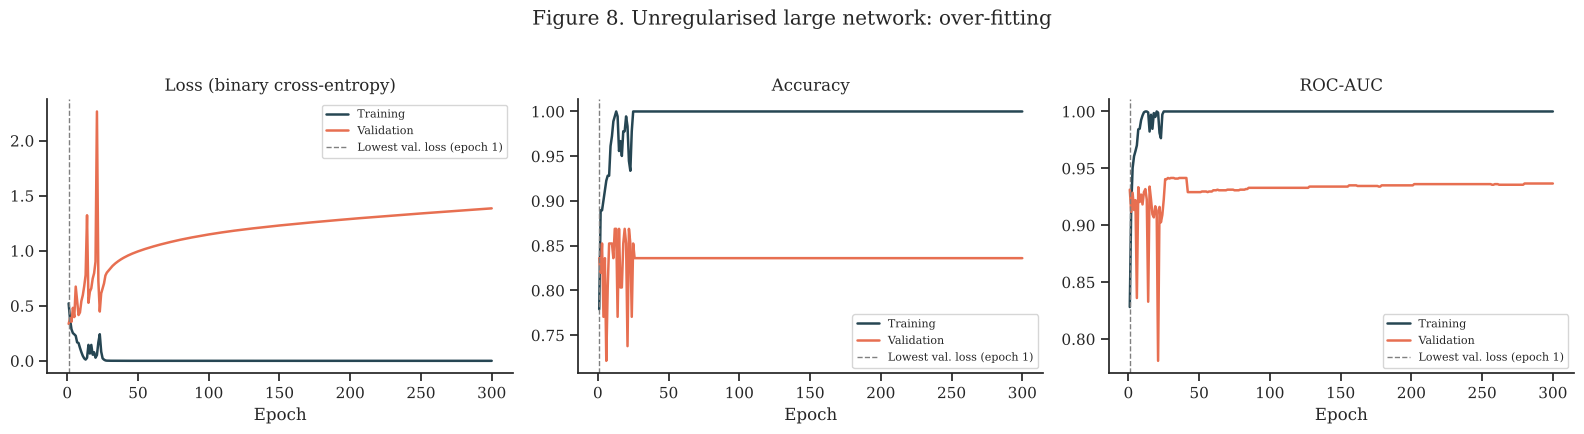

In [20]:
keras.utils.set_random_seed(SEED)
big = build_mlp(Xtr.shape[1], (128, 64, 32), 0.0, 0.0, 1e-2)
Hb = pd.DataFrame(big.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=300, batch_size=16, verbose=0).history)
big_best = int(Hb.val_loss.idxmin()) + 1
print("parameters: selected %d | large %d" % (mlp.count_params(), big.count_params()))
print("large NN: best val loss %.3f at epoch %d; final train loss %.4f, final val loss %.3f, final train acc %.3f, final val acc %.3f"
      % (Hb.val_loss.min(), big_best, Hb.loss.iloc[-1], Hb.val_loss.iloc[-1], Hb.accuracy.iloc[-1], Hb.val_accuracy.iloc[-1]))
curves(Hb, big_best, "Figure 8. Unregularised large network: over-fitting", "f08_nn_overfit")

**Over-fitting experiment (Figure 8).** The 13,185-parameter network (about 73 parameters per training patient) reaches its lowest validation loss after **one epoch** (0.336). It then memorises the training set: training loss reaches 0.0000 and training accuracy 100%, while validation loss climbs to **1.39**. Validation accuracy stays around 84%, but the model becomes extremely over-confident on the patients it gets wrong. The selected network avoids this through a smaller architecture (3,521 parameters), L2 weight decay, a low learning rate and early stopping. Dropout was tested in the search but did not improve the cross-validated AUC once L2 and early stopping were in place.

## 4.4 Training vs validation behaviour of the traditional models
**Learning curves** show cross-validated training and validation AUC as the amount of training data grows. A large, persistent gap means high variance (**overfitting**); two low, converging curves mean high bias (**underfitting**).

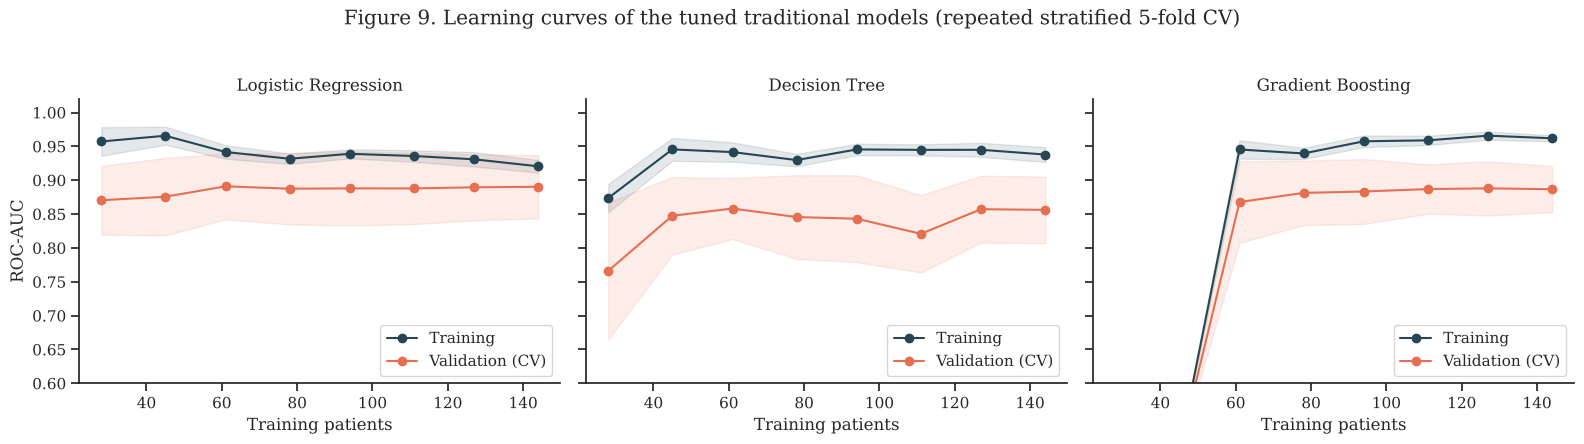

Logistic Regression  n= 28: train 0.957 / val 0.870   ->   n=144: train 0.921 / val 0.890  (gap 0.030)
Decision Tree        n= 28: train 0.874 / val 0.766   ->   n=144: train 0.938 / val 0.856  (gap 0.082)
Gradient Boosting    n= 28: train 0.500 / val 0.500   ->   n=144: train 0.962 / val 0.887  (gap 0.075)


In [21]:
best_est = {n: s.best_estimator_ for n, s in search.items()}
sizes = np.linspace(0.2, 1.0, 8)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
lc_out = {}
for ax, (name, est) in zip(axes, best_est.items()):
    n, tr, va = learning_curve(est, X_train, y_train, train_sizes=sizes, cv=rcv, scoring="roc_auc", n_jobs=-1)
    lc_out[name] = (n, tr.mean(1), va.mean(1))
    for sc, lab, col in [(tr, "Training", "#264653"), (va, "Validation (CV)", "#E76F51")]:
        ax.plot(n, sc.mean(1), "o-", color=col, label=lab)
        ax.fill_between(n, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=0.12)
    ax.set_title(name); ax.set_xlabel("Training patients"); ax.set_ylim(0.6, 1.02); ax.legend(loc="lower right")
axes[0].set_ylabel("ROC-AUC")
fig.suptitle("Figure 9. Learning curves of the tuned traditional models (repeated stratified 5-fold CV)", y=1.03)
save("f09_learning_curves")
for name, (n, tr, va) in lc_out.items():
    print(f"{name:20s} n={n[0]:3d}: train {tr[0]:.3f} / val {va[0]:.3f}   ->   n={n[-1]:3d}: train {tr[-1]:.3f} / val {va[-1]:.3f}  (gap {tr[-1]-va[-1]:.3f})")

**Learning curves (Figure 9)**
- **Logistic Regression:** the curves converge quickly (training 0.921, validation 0.890 at 144 patients; gap 0.03). This is a **low-variance** model, and more data would add little — the remaining error is mostly bias and irreducible noise.
- **Decision Tree:** the largest gap (0.08) and the lowest validation AUC (0.856). The validation curve is still rising, so the tree is **variance-limited** and would benefit most from more data.
- **Gradient Boosting:** with only 28 patients, both scores are 0.5. Because of `min_samples_leaf = 20`, the trees cannot split at all and the model predicts a constant — a clear case of **underfitting caused by over-strong regularisation on tiny data**. With the full training set it reaches 0.887 validation AUC with a moderate gap (0.075).

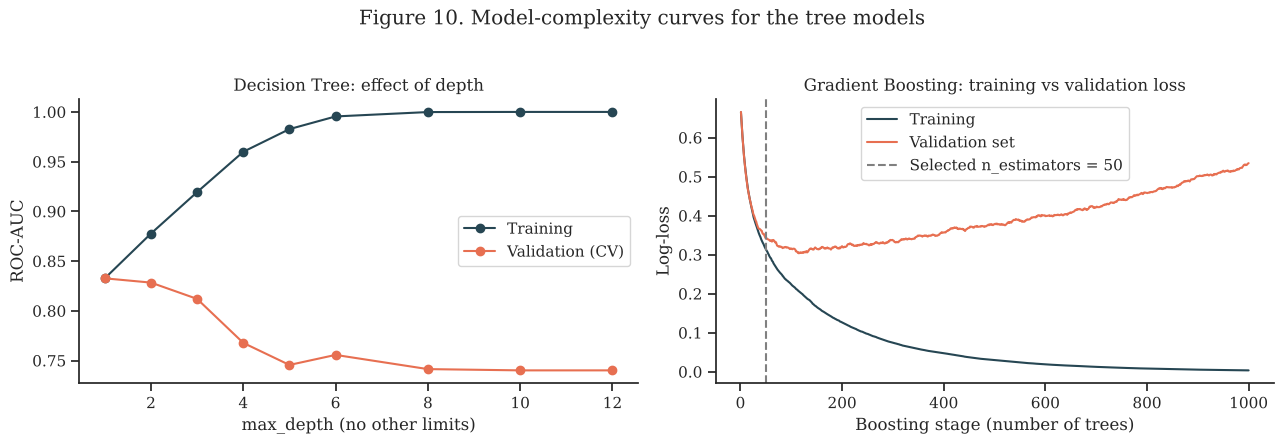

 depth  train   val
     1  0.833 0.833
     2  0.878 0.828
     3  0.919 0.812
     4  0.960 0.768
     5  0.983 0.746
     6  0.995 0.756
     8  1.000 0.741
    10  1.000 0.740
    12  1.000 0.740
GB long run: min val loss 0.303 at 115 trees; at 1000 trees train 0.003, val 0.534


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12]
dt_unpruned = Pipeline([("prep", make_preprocessor(True)), ("clf", DecisionTreeClassifier(random_state=SEED))])
tr, va = validation_curve(dt_unpruned, X_train, y_train, param_name="clf__max_depth", param_range=depths,
                          cv=rcv, scoring="roc_auc", n_jobs=-1)
axes[0].plot(depths, tr.mean(1), "o-", color="#264653", label="Training")
axes[0].plot(depths, va.mean(1), "o-", color="#E76F51", label="Validation (CV)")
axes[0].set_xlabel("max_depth (no other limits)"); axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("Decision Tree: effect of depth"); axes[0].legend()
dt_vc = pd.DataFrame({"depth": depths, "train": tr.mean(1), "val": va.mean(1)})

gb = best_est["Gradient Boosting"]
Xtr_t, Xva_t = gb["prep"].transform(X_train), gb["prep"].transform(X_val)
gb_curve = pd.DataFrame({
    "stage": np.arange(1, gb["clf"].n_estimators_ + 1),
    "train_loss": [log_loss(y_train, p[:, 1]) for p in gb["clf"].staged_predict_proba(Xtr_t)],
    "val_loss": [log_loss(y_val, p[:, 1]) for p in gb["clf"].staged_predict_proba(Xva_t)]})
# continue boosting far beyond the tuned number of trees to expose over-fitting
gb_long = GradientBoostingClassifier(**{**gb["clf"].get_params(), "n_estimators": 1000}).fit(Xtr_t, y_train)
gb_long_curve = pd.DataFrame({
    "stage": np.arange(1, 1001),
    "train_loss": [log_loss(y_train, p[:, 1]) for p in gb_long.staged_predict_proba(Xtr_t)],
    "val_loss": [log_loss(y_val, p[:, 1]) for p in gb_long.staged_predict_proba(Xva_t)]})
axes[1].plot(gb_long_curve.stage, gb_long_curve.train_loss, color="#264653", label="Training")
axes[1].plot(gb_long_curve.stage, gb_long_curve.val_loss, color="#E76F51", label="Validation set")
axes[1].axvline(gb["clf"].n_estimators_, color="grey", ls="--", label=f"Selected n_estimators = {gb['clf'].n_estimators_}")
axes[1].set_xlabel("Boosting stage (number of trees)"); axes[1].set_ylabel("Log-loss")
axes[1].set_title("Gradient Boosting: training vs validation loss"); axes[1].legend()
fig.suptitle("Figure 10. Model-complexity curves for the tree models", y=1.03)
save("f10_complexity_curves")
print(dt_vc.round(3).to_string(index=False))
i_min = gb_long_curve.val_loss.idxmin()
print("GB long run: min val loss %.3f at %d trees; at 1000 trees train %.3f, val %.3f"
      % (gb_long_curve.val_loss.min(), gb_long_curve.stage[i_min], gb_long_curve.train_loss.iloc[-1], gb_long_curve.val_loss.iloc[-1]))

**Complexity curves (Figure 10)**
- **Decision Tree depth:** depth 1–2 gives similar training and validation AUC (≈ 0.83). From depth 3 onwards, training AUC rises to 1.0 while validation AUC *falls* to 0.74 — textbook **overfitting** of an unrestricted tree. This is why the tuned tree combines depth with minimum leaf size and cost-complexity pruning, instead of relying on depth alone.
- **Gradient Boosting stages:** validation log-loss reaches its minimum (0.303) at about 115 trees and then rises steadily to 0.53 at 1,000 trees, while training loss goes to almost 0. The CV-selected 50 trees with a slow learning rate keep the model on the safe, left side of this curve.

## 4.5 Training vs validation performance of all tuned models

In [23]:
def proba(name, Xdf):
    if name == "Neural Network":
        return mlp(prep_nn.transform(Xdf).astype("float32"), training=False).numpy().ravel()
    return best_est[name].predict_proba(Xdf)[:, 1]

def metrics(y_true, p, thr=0.5):
    yhat = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    return {"Accuracy": (tp + tn) / len(y_true), "Precision": precision_score(y_true, yhat, zero_division=0),
            "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp), "F1": f1_score(y_true, yhat),
            "ROC-AUC": roc_auc_score(y_true, p), "TP": tp, "FN": fn, "FP": fp, "TN": tn}

NAMES = ["Logistic Regression", "Decision Tree", "Gradient Boosting", "Neural Network"]
tv = []
for n in NAMES:
    a, b = metrics(y_train, proba(n, X_train)), metrics(y_val, proba(n, X_val))
    tv.append({"Model": n, "Train AUC": a["ROC-AUC"], "Val AUC": b["ROC-AUC"], "AUC gap": a["ROC-AUC"] - b["ROC-AUC"],
               "Train acc": a["Accuracy"], "Val acc": b["Accuracy"], "Val recall": b["Recall"], "Val F1": b["F1"]})
trainval = pd.DataFrame(tv); trainval.to_csv("results/train_val.csv", index=False); trainval.round(3)

,Model,Train AUC,Val AUC,AUC gap,Train acc,Val acc,Val recall,Val F1
0,Logistic Regression,0.919,0.943,-0.023,0.867,0.852,0.893,0.847
1,Decision Tree,0.933,0.923,0.010,0.845,0.836,0.893,0.833
2,Gradient Boosting,0.964,0.938,0.025,0.873,0.836,0.786,0.815
3,Neural Network,0.939,0.937,0.002,0.901,0.852,0.893,0.847


On the separate validation set, all four tuned models generalise well (validation AUC 0.92–0.94). **Logistic Regression has a slightly *higher* validation AUC than training AUC (0.943 vs 0.919)** — not a problem, just sampling noise with 61 patients. Gradient Boosting shows the largest training–validation gap and the lowest validation recall (0.786). Logistic Regression and the Neural Network share the best validation accuracy (0.852), recall (0.893) and F1 (0.847).

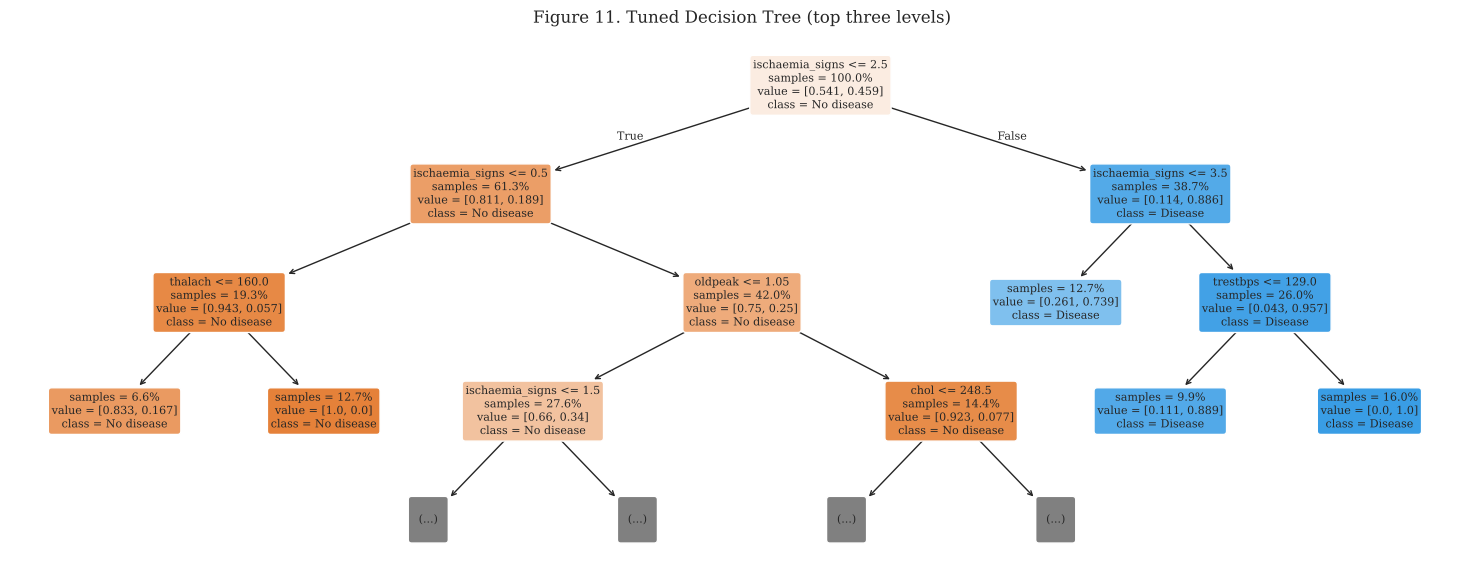

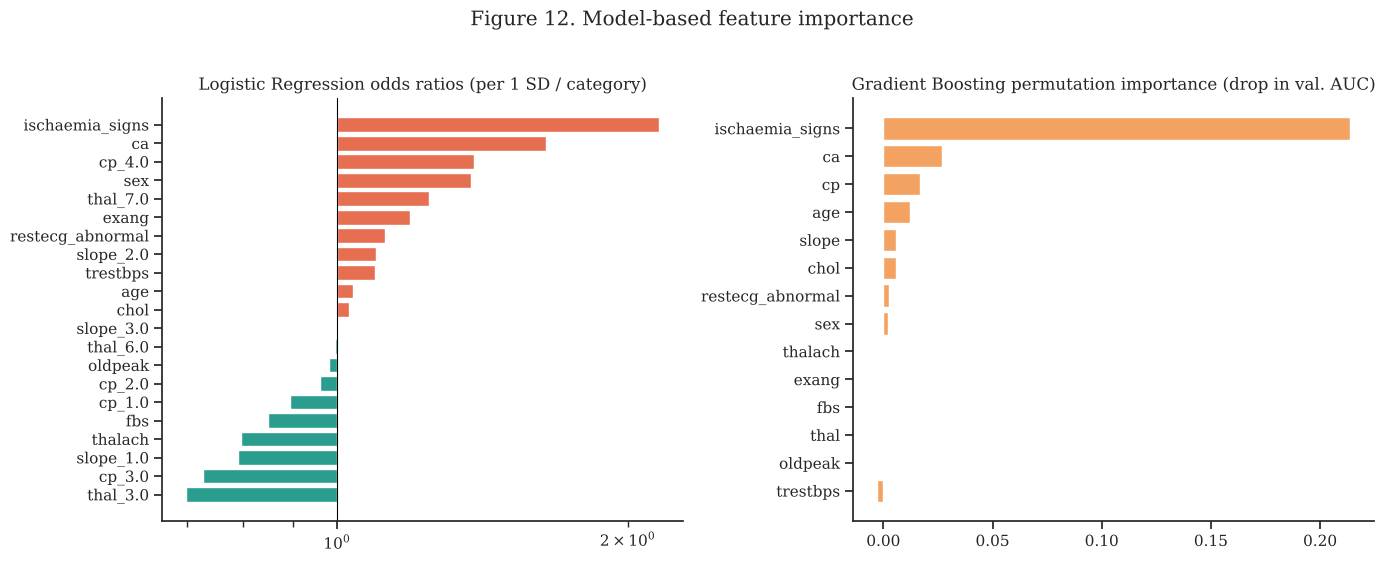

Odds ratios (non-zero):
 thal_3.0            0.70
cp_3.0              0.73
slope_1.0           0.79
thalach             0.80
fbs                 0.85
cp_1.0              0.89
cp_2.0              0.96
oldpeak             0.98
thal_6.0            1.00
slope_3.0           1.00
chol                1.03
age                 1.04
trestbps            1.10
slope_2.0           1.10
restecg_abnormal    1.12
exang               1.19
thal_7.0            1.25
sex                 1.38
cp_4.0              1.39
ca                  1.65
ischaemia_signs     2.16

Permutation importance:
 ischaemia_signs     0.214
ca                  0.027
cp                  0.017
age                 0.012
slope               0.006
chol                0.006
restecg_abnormal    0.002
sex                 0.002
thalach             0.000
fbs                 0.000
exang               0.000
thal               -0.000
oldpeak            -0.000
trestbps           -0.003


In [24]:
fig = plt.figure(figsize=(15, 6))
dt = best_est["Decision Tree"]
plot_tree(dt["clf"], feature_names=list(dt["prep"].get_feature_names_out()), class_names=["No disease", "Disease"],
          filled=True, rounded=True, max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title("Figure 11. Tuned Decision Tree (top three levels)")
save("f11_decision_tree")

lr = best_est["Logistic Regression"]
coef = pd.Series(lr["clf"].coef_.ravel(), index=lr["prep"].get_feature_names_out())
odds = np.exp(coef).sort_values()
pi = permutation_importance(best_est["Gradient Boosting"], X_val, y_val, scoring="roc_auc", n_repeats=50, random_state=SEED)
pimp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
nz = odds[coef[odds.index] != 0]
axes[0].barh(nz.index, nz.values - 1, left=1, color=[C_YES if v > 1 else C_NO for v in nz.values])
axes[0].axvline(1, color="black", lw=0.8); axes[0].set_xscale("log")
axes[0].set_title("Logistic Regression odds ratios (per 1 SD / category)")
axes[1].barh(pimp.index, pimp.values, color="#F4A261")
axes[1].set_title("Gradient Boosting permutation importance (drop in val. AUC)")
fig.suptitle("Figure 12. Model-based feature importance", y=1.02)
save("f12_importance")
print("Odds ratios (non-zero):\n", nz.round(2).to_string())
print("\nPermutation importance:\n", pimp.sort_values(ascending=False).round(3).to_string())

**Model-based relevance.** Both models confirm the EDA. In Logistic Regression, the largest odds ratios (per standard deviation or per category) are **ischaemia_signs (2.16)**, **ca (1.65)**, asymptomatic chest pain **cp_4 (1.39)**, **male sex (1.38)** and a reversible thallium defect **thal_7 (1.25)**. A normal thallium scan (thal_3, 0.70), non-anginal pain (cp_3, 0.73), an up-sloping ST segment (0.79) and a higher maximum heart rate (0.80) are protective. In Gradient Boosting, permuting `ischaemia_signs` lowers validation AUC by 0.21, far more than any other feature. The engineered feature has absorbed most of the information in exang, oldpeak and thal, which therefore show near-zero importance on their own. The Decision Tree (Figure 11) also uses it for its first two splits.

---
# Stage 5 — Final Evaluation on the Test Set
The 61 test patients (28 with disease) are used **once**, with all hyperparameters frozen and the standard 0.5 probability threshold.

**Metrics**
- **Recall (sensitivity)** — share of diseased patients detected. A false negative sends a patient with heart disease home without treatment, so this is the most important clinical metric.
- **Specificity** — share of healthy patients correctly cleared. Low specificity causes unnecessary invasive angiography.
- **Precision** — how reliable a positive prediction is.
- **F1** — balances precision and recall in one number.
- **ROC-AUC** — threshold-free ranking quality; also the tuning metric, so the evaluation is consistent with model selection.
- **Accuracy** — meaningful here because the classes are nearly balanced.
- **Confusion matrix** — exact counts of missed and false-alarm patients.

Because 61 patients is a small sample, **95% bootstrap confidence intervals** (2,000 resamples) are added for AUC and F1.

In [25]:
boot = np.random.default_rng(SEED)
idx = [boot.integers(0, len(y_test), len(y_test)) for _ in range(2000)]
test_rows, P = [], {}
for n in NAMES:
    p = proba(n, X_test); P[n] = p; m = metrics(y_test, p)
    auc_b = [roc_auc_score(y_test[i], p[i]) for i in idx if 0 < y_test[i].sum() < len(i)]
    f1_b = [f1_score(y_test[i], (p[i] >= .5).astype(int)) for i in idx]
    test_rows.append({"Model": n, **m, "AUC 95% CI": f"[{np.percentile(auc_b, 2.5):.3f}, {np.percentile(auc_b, 97.5):.3f}]",
                      "F1 95% CI": f"[{np.percentile(f1_b, 2.5):.3f}, {np.percentile(f1_b, 97.5):.3f}]"})
test = pd.DataFrame(test_rows); test.to_csv("results/test.csv", index=False); test.round(3)

,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,TP,FN,FP,TN,AUC 95% CI,F1 95% CI
0,Logistic Regression,0.885,0.889,0.857,0.909,0.873,0.929,24,4,3,30,"[0.855, 0.983]","[0.772, 0.955]"
1,Decision Tree,0.820,0.774,0.857,0.788,0.814,0.898,24,4,7,26,"[0.806, 0.973]","[0.690, 0.909]"
2,Gradient Boosting,0.852,0.880,0.786,0.909,0.830,0.949,22,6,3,30,"[0.898, 0.988]","[0.706, 0.929]"
3,Neural Network,0.869,0.885,0.821,0.909,0.852,0.919,23,5,3,30,"[0.846, 0.975]","[0.744, 0.941]"


**Test results.** Logistic Regression achieves the best accuracy (0.885), precision (0.889), F1 (0.873) and specificity (0.909, shared), and it misses 4 of 28 diseased patients. Gradient Boosting ranks patients best (AUC 0.949) but, at the 0.5 threshold, misses the most diseased patients (6). The Decision Tree detects as many diseased patients as Logistic Regression (24/28) but raises the most false alarms (7). The Neural Network is second on accuracy and F1. **All confidence intervals overlap widely** (e.g., F1 between about 0.69 and 0.96), so with 61 test patients none of these differences is statistically conclusive.

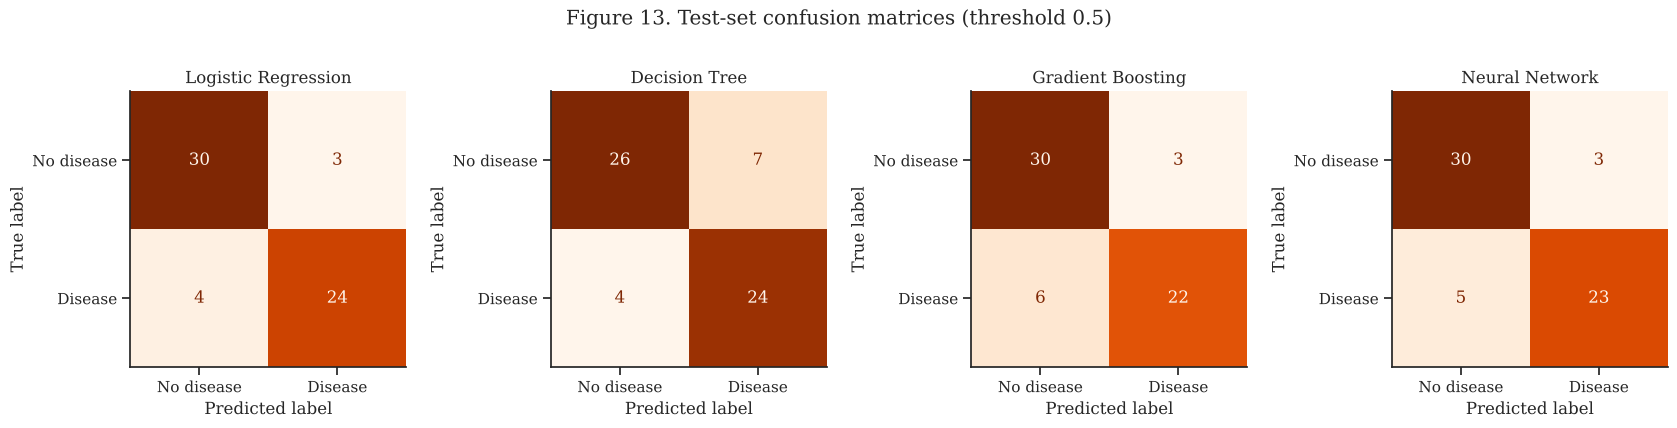

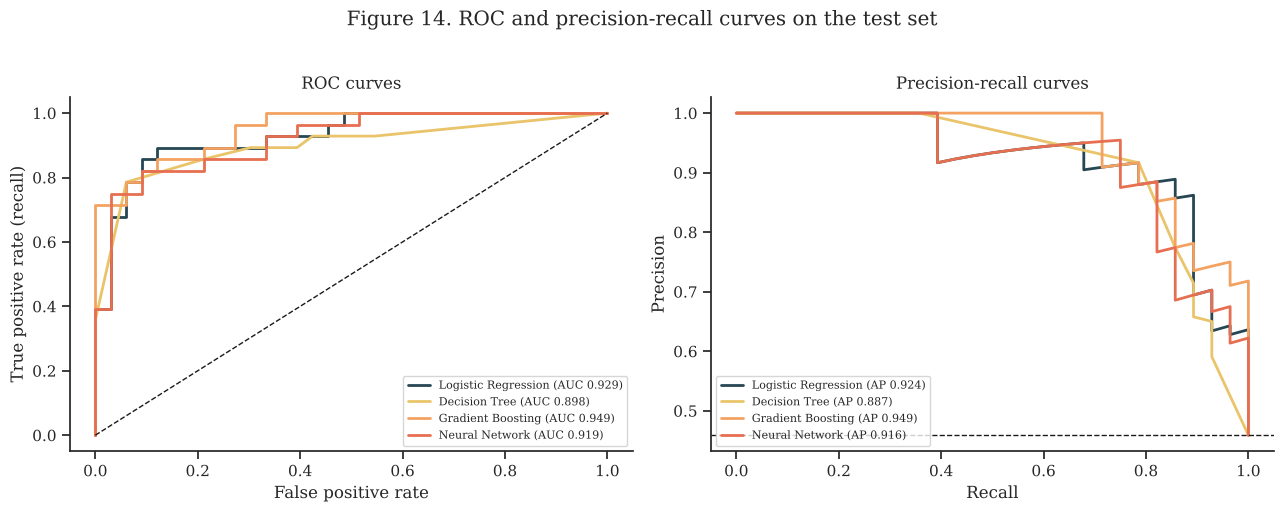

 Logistic Regression
              precision    recall  f1-score   support

  No disease      0.882     0.909     0.896        33
     Disease      0.889     0.857     0.873        28

    accuracy                          0.885        61
   macro avg      0.886     0.883     0.884        61
weighted avg      0.885     0.885     0.885        61

 Decision Tree
              precision    recall  f1-score   support

  No disease      0.867     0.788     0.825        33
     Disease      0.774     0.857     0.814        28

    accuracy                          0.820        61
   macro avg      0.820     0.823     0.819        61
weighted avg      0.824     0.820     0.820        61

 Gradient Boosting
              precision    recall  f1-score   support

  No disease      0.833     0.909     0.870        33
     Disease      0.880     0.786     0.830        28

    accuracy                          0.852        61
   macro avg      0.857     0.847     0.850        61
weighted avg      0

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, n in zip(axes, NAMES):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (P[n] >= .5).astype(int)), display_labels=["No disease", "Disease"]).plot(
        ax=ax, cmap="Oranges", colorbar=False, values_format="d")
    ax.set_title(n); ax.grid(False)
fig.suptitle("Figure 13. Test-set confusion matrices (threshold 0.5)", y=1.04)
save("f13_confusion")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n in NAMES:
    f, t, _ = roc_curve(y_test, P[n]); axes[0].plot(f, t, lw=2, color=MODEL_COLORS[n], label=f"{n} (AUC {roc_auc_score(y_test, P[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, P[n]); axes[1].plot(rc, pr, lw=2, color=MODEL_COLORS[n], label=f"{n} (AP {average_precision_score(y_test, P[n]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves"); axes[1].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure 14. ROC and precision-recall curves on the test set", y=1.02)
save("f14_roc_pr")
for n in NAMES:
    print("=" * 55, "\n", n); print(classification_report(y_test, (P[n] >= .5).astype(int), target_names=["No disease", "Disease"], digits=3))

,Model,CV AUC,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,FN,FP,Val AUC
0,Logistic Regression,0.891,0.885,0.889,0.857,0.909,0.873,0.929,4,3,0.943
1,Decision Tree,0.856,0.820,0.774,0.857,0.788,0.814,0.898,4,7,0.923
2,Gradient Boosting,0.883,0.852,0.880,0.786,0.909,0.830,0.949,6,3,0.938
3,Neural Network,0.892,0.869,0.885,0.821,0.909,0.852,0.919,5,3,0.937


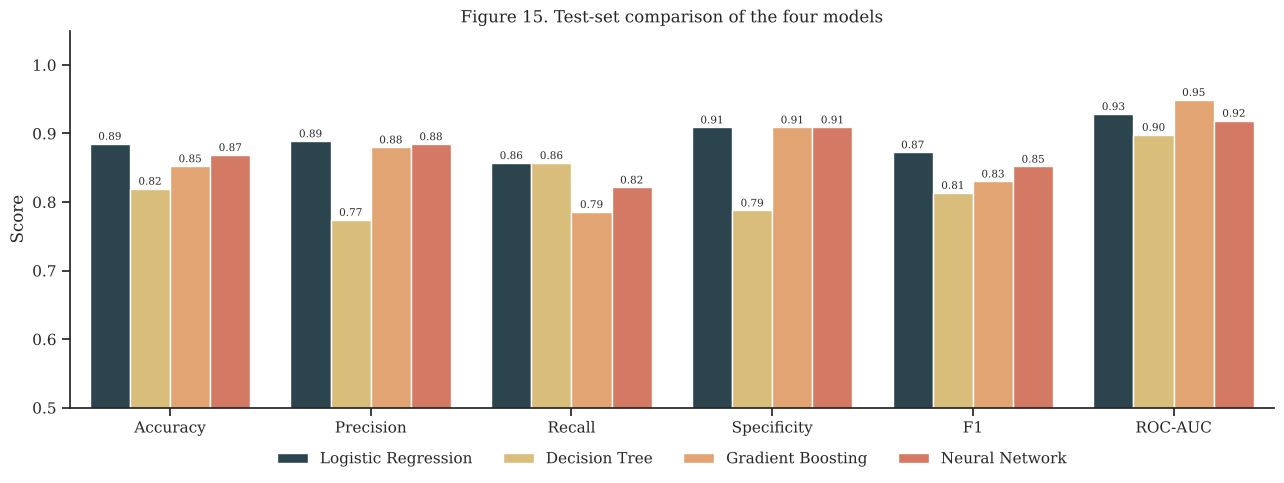

saved


In [27]:
comp = test[["Model", "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "FN", "FP"]].merge(
    trainval[["Model", "Val AUC"]], on="Model")
comp.insert(1, "CV AUC", [tuning.set_index("Model").loc[n, "CV val AUC"] if n != "Neural Network" else nn_search.iloc[0]["CV AUC"] for n in comp.Model])
display(comp.round(3))
long = comp.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"], var_name="Metric")
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=long, x="Metric", y="value", hue="Model", palette=MODEL_COLORS, ax=ax)
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=7.5, padding=1)
ax.set_ylim(0.5, 1.05); ax.set_xlabel(""); ax.set_ylabel("Score")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.set_title("Figure 15. Test-set comparison of the four models")
save("f15_comparison")

json.dump({"best_cfg": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_cfg.items()},
           "nn_params": int(mlp.count_params()), "big_params": int(big.count_params()),
           "nn_epochs": len(H), "nn_best_epoch": best_ep, "nn_best": H.iloc[best_ep - 1].to_dict(),
           "nn_final": H.iloc[-1].to_dict(),
           "big_best_epoch": big_best, "big_min_val_loss": float(Hb.val_loss.min()),
           "big_final": Hb.iloc[-1].to_dict(), "nn_search_time": nn_time,
           "gb_n_estimators": int(gb["clf"].n_estimators_),
           "gb_long_min_val": float(gb_long_curve.val_loss.min()), "gb_long_min_stage": int(gb_long_curve.stage[i_min]),
           "gb_long_final_train": float(gb_long_curve.train_loss.iloc[-1]), "gb_long_final_val": float(gb_long_curve.val_loss.iloc[-1]),
           "learning_curves": {k: {"n": v[0].tolist(), "train": v[1].tolist(), "val": v[2].tolist()} for k, v in lc_out.items()},
           "dt_depth_curve": dt_vc.to_dict(orient="list"), "odds_ratios": nz.to_dict(), "perm_importance": pimp.to_dict(),
           "fences": {c: [float(a), float(b)] for c, a, b in zip(CONT_F, prep.named_transformers_["cont"]["cap"].lower_, prep.named_transformers_["cont"]["cap"].upper_)}},
          open("results/summary.json", "w"), indent=2, default=float)
comp.to_csv("results/comparison.csv", index=False)
print("saved")

## Discussion and final choice
**Most suitable model: Logistic Regression.** It has the joint-best cross-validated AUC (0.891 vs the NN's 0.892, a negligible difference), the best validation AUC (0.943), the smallest generalisation gap, and the best test accuracy and F1 (0.885 / 0.873), with only 4 missed cases. It is also the most transparent model: its odds ratios can be explained directly to clinicians.

**Neural Network vs traditional models.** The tuned NN matches Logistic Regression in cross-validation and on the validation set, and comes second on the test set (one more missed patient). It brings no measurable gain because the signal in this dataset is largely additive (risk factors add up, as the strength of `ischaemia_signs` shows). The NN also has higher fold-to-fold variance, needed about 6 minutes of search compared with 15 seconds for Logistic Regression, and overfits within one epoch when it is not regularised. The two tree models capture interactions but are either unstable (Decision Tree) or under-sensitive at the default threshold (Gradient Boosting).

**Clinical note.** For screening, a missed case is worse than a false alarm. Lowering the threshold (e.g., to 0.4) on validation data would raise recall for every model. Gradient Boosting's high AUC suggests it would benefit most from such tuning.

## Conclusion and future work
A leakage-free pipeline (mode/median imputation, IQR capping and scaling for scale-sensitive models, one-hot encoding, a clinically motivated composite feature) and repeated cross-validation produced four models with 82–89% test accuracy. Logistic Regression is the recommended model. Future work: validate on the other UCI sites (Hungary, Switzerland, Long Beach VA); tune the decision threshold for a target sensitivity; use nested cross-validation on the full dataset to compare models more reliably; and add calibration and SHAP explanations.